In [8]:

%pip install medmnist numpy pandas scipy matplotlib seaborn scikit-learn Pillow jupyter ipykernel ipywidgets torchmetrics tensorboard joblib pytest


  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached tensorboard_data_server-0.7.2-py3-none-any.whl.metadata (1.1 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached beautifulsoup4-4.15.0-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.3 MB 4.5 MB/s eta 0:00:02
   ------- -------------------------------- 1.8/9.3 MB 4.9 MB/s eta 0:00:02
   ------------- -------------------------- 3.1/9.3 MB 5.2 MB/s eta 0:00:02
   ----------------- ---------------------- 4.2/9.3 MB 5.2 MB/s eta 0:00:01
   ----------------------- ---------------- 5.5/9.3 MB 5.4 MB/s eta 0:00:01
   ----------------------------- ---------- 6.8/9.3 MB 5.6 MB/s eta 0:00:01
   ---------------------------------- ----- 8.1/9.3 MB 5.8 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
from medmnist import PneumoniaMNIST
from medmnist import INFO

info = INFO["pneumoniamnist"]
print(info)

{'python_class': 'PneumoniaMNIST', 'description': 'The PneumoniaMNIST is based on a prior dataset of 5,856 pediatric chest X-Ray images. The task is binary-class classification of pneumonia against normal. We split the source training set with a ratio of 9:1 into training and validation set and use its source validation set as the test set. The source images are gray-scale, and their sizes are (384−2,916)×(127−2,713). We center-crop the images and resize them into 1×28×28.', 'url': 'https://zenodo.org/records/10519652/files/pneumoniamnist.npz?download=1', 'MD5': '28209eda62fecd6e6a2d98b1501bb15f', 'url_64': 'https://zenodo.org/records/10519652/files/pneumoniamnist_64.npz?download=1', 'MD5_64': '8f4eceb4ccffa70c672198ea285246c6', 'url_128': 'https://zenodo.org/records/10519652/files/pneumoniamnist_128.npz?download=1', 'MD5_128': '05b46931834c231683c68f40c47b2971', 'url_224': 'https://zenodo.org/records/10519652/files/pneumoniamnist_224.npz?download=1', 'MD5_224': 'd6a3c71de1b945ea11211b

In [3]:

from pathlib import Path
from medmnist import PneumoniaMNIST

# Resolve the path from the project root, regardless of notebook working directory
project_root = Path.cwd()

while project_root.name != "medsecure-ai" and project_root != project_root.parent:
    project_root = project_root.parent

if project_root.name != "medsecure-ai":
    raise FileNotFoundError(
        "Could not locate the medsecure-ai project root. "
        "Open the notebook from your project workspace."
    )

data_dir = project_root / "ml" / "data"
data_dir.mkdir(parents=True, exist_ok=True)

print("Dataset directory:", data_dir)


Dataset directory: c:\Users\dhwan\OneDrive\Desktop\5_ISC_PROJECT\medsecure-ai\ml\data


In [4]:

train_dataset = PneumoniaMNIST(
    split="train",
    root=str(data_dir),
    download=True
)

val_dataset = PneumoniaMNIST(
    split="val",
    root=str(data_dir),
    download=True
)

test_dataset = PneumoniaMNIST(
    split="test",
    root=str(data_dir),
    download=True
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))


100%|██████████| 4.17M/4.17M [00:55<00:00, 74.7kB/s]

Train: 4708
Validation: 524
Test: 624


In [5]:

image, label = train_dataset[0]

print("Image size:", image.size)
print("Image mode:", image.mode)
print("Label:", label)


Image size: (28, 28)
Image mode: L
Label: [1]


In [6]:

import numpy as np
import pandas as pd

def get_label_counts(dataset, split_name):
    labels = np.array(dataset.labels).reshape(-1).astype(int)
    counts = np.bincount(labels, minlength=2)

    return {
        "Split": split_name,
        "Total": len(labels),
        "Normal (0)": counts[0],
        "Pneumonia (1)": counts[1],
        "Pneumonia (%)": round(100 * counts[1] / len(labels), 2),
    }

distribution = pd.DataFrame([
    get_label_counts(train_dataset, "Train"),
    get_label_counts(val_dataset, "Validation"),
    get_label_counts(test_dataset, "Test"),
])

display(distribution)


,Split,Total,Normal (0),Pneumonia (1),Pneumonia (%)
0,Train,4708,1214,3494,74.21
1,Validation,524,135,389,74.24
2,Test,624,234,390,62.50


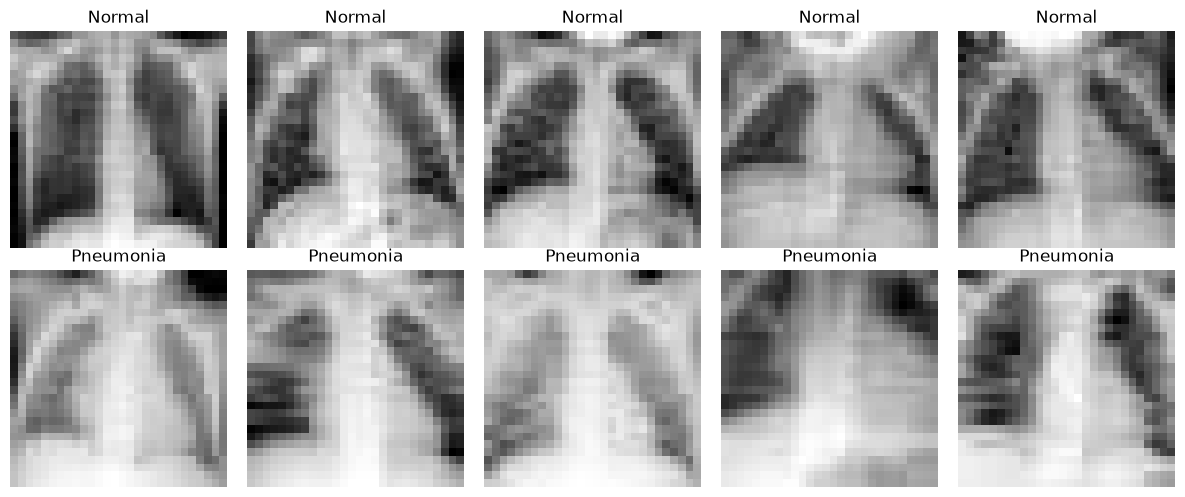

In [9]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for class_label, row in [(0, 0), (1, 1)]:
    indices = np.where(
        np.array(train_dataset.labels).reshape(-1) == class_label
    )[0][:5]

    for col, idx in enumerate(indices):
        image, label = train_dataset[int(idx)]
        axes[row, col].imshow(image, cmap="gray")
        axes[row, col].set_title(
            "Pneumonia" if class_label == 1 else "Normal"
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


In [10]:

from medmnist import INFO

info = INFO["pneumoniamnist"]
print("Label mapping:", info["label"])
print("Number of classes:", len(info["label"]))
print("Task:", info["task"])


Label mapping: {'0': 'normal', '1': 'pneumonia'}
Number of classes: 2
Task: binary-class


In [11]:

import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Use GPU if available; otherwise CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

class PneumoniaTensorDataset(Dataset):
    def __init__(self, medmnist_dataset):
        self.images = medmnist_dataset.imgs
        self.labels = np.asarray(medmnist_dataset.labels).reshape(-1).astype(np.int64)

        self.transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.5], std=[0.5])
        ])

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        image = self.images[idx]
        image = self.transform(image)
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        return image, label

train_data = PneumoniaTensorDataset(train_dataset)
val_data = PneumoniaTensorDataset(val_dataset)
test_data = PneumoniaTensorDataset(test_dataset)

BATCH_SIZE = 64

train_loader = DataLoader(
    train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
)
val_loader = DataLoader(
    val_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)
test_loader = DataLoader(
    test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels in batch:", labels.unique().tolist())


Device: cpu
Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])
Labels in batch: [0, 1]


In [12]:

import torch.nn as nn

class PneumoniaCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = PneumoniaCNN().to(device)

print(model)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)


PneumoniaCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=64, out_features=2, bias=True)
  )
)
Trainable parameters: 23426


In [13]:

import copy
import time
from pathlib import Path

import torch.nn as nn
import torch.optim as optim

# Paths
ARTIFACT_DIR = project_root / "ml" / "artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = ARTIFACT_DIR / "pneumonia_cnn_best.pt"

# Loss and optimizer
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

EPOCHS = 15
best_val_loss = float("inf")
best_epoch = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

print("Model path:", MODEL_PATH)
print("Epochs:", EPOCHS)
print("Optimizer: Adam")
print("Loss: CrossEntropyLoss")


Model path: c:\Users\dhwan\OneDrive\Desktop\5_ISC_PROJECT\medsecure-ai\ml\artifacts\pneumonia_cnn_best.pt
Epochs: 15
Optimizer: Adam
Loss: CrossEntropyLoss


In [14]:

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for batch_images, batch_labels in loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            logits = model(batch_images)
            loss = criterion(logits, batch_labels)

            if training:
                loss.backward()
                optimizer.step()

        batch_size = batch_labels.size(0)
        total_loss += loss.item() * batch_size
        predictions = logits.argmax(dim=1)
        correct += (predictions == batch_labels).sum().item()
        total += batch_size

    return total_loss / total, correct / total


start_time = time.time()

for epoch in range(EPOCHS):
    train_loss, train_acc = run_epoch(
        model, train_loader, criterion, optimizer
    )
    val_loss, val_acc = run_epoch(
        model, val_loader, criterion
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_acc)
    history["val_accuracy"].append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1

        torch.save(
            {
                "epoch": best_epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_loss": best_val_loss,
                "class_mapping": {"0": "normal", "1": "pneumonia"},
                "seed": SEED
            },
            MODEL_PATH
        )

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train acc: {train_acc:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val acc: {val_acc:.4f}"
    )

print(f"\nBest epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Training time: {(time.time() - start_time) / 60:.2f} minutes")
print(f"Saved checkpoint: {MODEL_PATH}")


Epoch 01/15 | Train loss: 0.5582 | Train acc: 0.7385 | Val loss: 0.4786 | Val acc: 0.7576
Epoch 02/15 | Train loss: 0.3982 | Train acc: 0.8129 | Val loss: 0.3505 | Val acc: 0.8244
Epoch 03/15 | Train loss: 0.3223 | Train acc: 0.8655 | Val loss: 0.2923 | Val acc: 0.8740
Epoch 04/15 | Train loss: 0.2609 | Train acc: 0.8949 | Val loss: 0.2780 | Val acc: 0.8721
Epoch 05/15 | Train loss: 0.2490 | Train acc: 0.9006 | Val loss: 0.2618 | Val acc: 0.8702
Epoch 06/15 | Train loss: 0.2201 | Train acc: 0.9110 | Val loss: 0.2284 | Val acc: 0.9103
Epoch 07/15 | Train loss: 0.2098 | Train acc: 0.9119 | Val loss: 0.2019 | Val acc: 0.9198
Epoch 08/15 | Train loss: 0.1951 | Train acc: 0.9244 | Val loss: 0.1883 | Val acc: 0.9275
Epoch 09/15 | Train loss: 0.1891 | Train acc: 0.9250 | Val loss: 0.1866 | Val acc: 0.9218
Epoch 10/15 | Train loss: 0.1847 | Train acc: 0.9305 | Val loss: 0.2464 | Val acc: 0.8912
Epoch 11/15 | Train loss: 0.1805 | Train acc: 0.9312 | Val loss: 0.1858 | Val acc: 0.9294
Epoch 12/1

Best checkpoint epoch: 15

Test metrics:
Accuracy: 0.8526
Precision (pneumonia): 0.8170
Sensitivity / Recall (pneumonia): 0.9846
Specificity (normal): 0.6325
F1-score (pneumonia): 0.8930
ROC-AUC: 0.9543
Average Precision (PR-AUC): 0.9637

Confusion counts: TN=148, FP=86, FN=6, TP=384

Classification report:
              precision    recall  f1-score   support

      Normal       0.96      0.63      0.76       234
   Pneumonia       0.82      0.98      0.89       390

    accuracy                           0.85       624
   macro avg       0.89      0.81      0.83       624
weighted avg       0.87      0.85      0.84       624



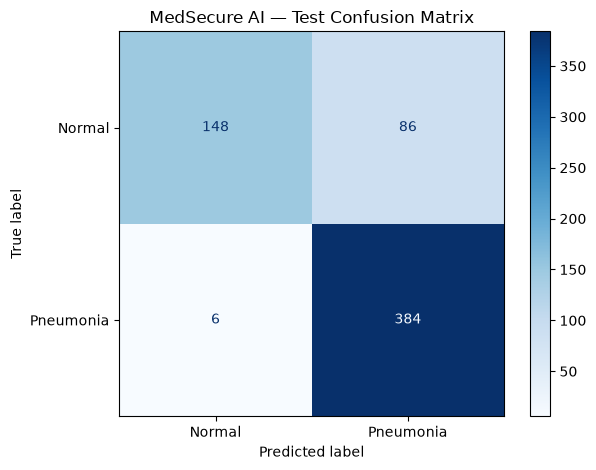

In [15]:

import numpy as np
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

# Load the best validation checkpoint
checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

all_labels = []
all_predictions = []
all_probabilities = []

# Evaluate on the official test set
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        logits = model(images)
        probabilities = torch.softmax(logits, dim=1)[:, 1]
        predictions = logits.argmax(dim=1)

        all_labels.extend(labels.numpy().tolist())
        all_predictions.extend(predictions.cpu().numpy().tolist())
        all_probabilities.extend(probabilities.cpu().numpy().tolist())

y_true = np.array(all_labels)
y_pred = np.array(all_predictions)
y_prob = np.array(all_probabilities)

# Confusion matrix: rows = actual, columns = predicted
tn, fp, fn, tp = confusion_matrix(
    y_true, y_pred, labels=[0, 1]
).ravel()

sensitivity = tp / (tp + fn) if (tp + fn) else 0.0
specificity = tn / (tn + fp) if (tn + fp) else 0.0

results = {
    "Accuracy": accuracy_score(y_true, y_pred),
    "Precision (pneumonia)": precision_score(
        y_true, y_pred, zero_division=0
    ),
    "Sensitivity / Recall (pneumonia)": sensitivity,
    "Specificity (normal)": specificity,
    "F1-score (pneumonia)": f1_score(
        y_true, y_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_true, y_prob),
    "Average Precision (PR-AUC)": average_precision_score(
        y_true, y_prob
    ),
}

print("Best checkpoint epoch:", checkpoint["epoch"])
print("\nTest metrics:")
for metric, value in results.items():
    print(f"{metric}: {value:.4f}")

print(f"\nConfusion counts: TN={tn}, FP={fp}, FN={fn}, TP={tp}")

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Normal", "Pneumonia"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=[0, 1],
    display_labels=["Normal", "Pneumonia"],
    cmap="Blues"
)
plt.title("MedSecure AI — Test Confusion Matrix")
plt.tight_layout()
plt.show()


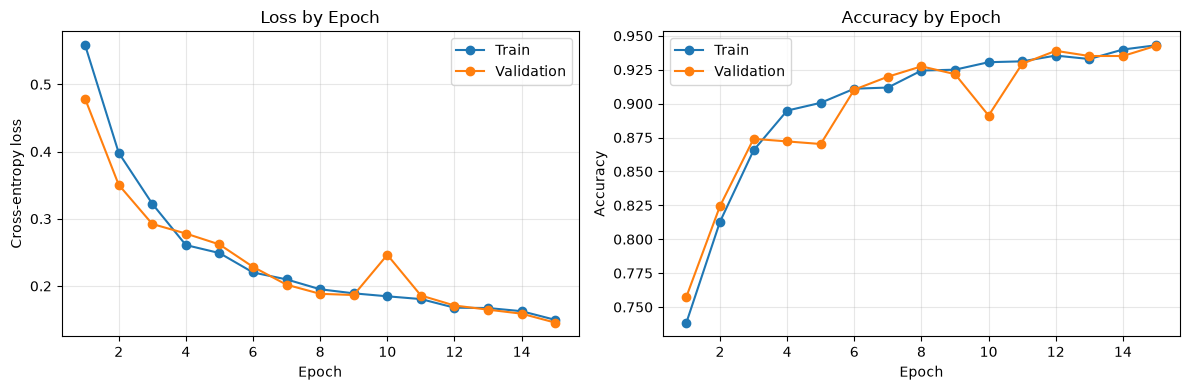

In [16]:

import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history["train_loss"], marker="o", label="Train")
axes[0].plot(epochs, history["val_loss"], marker="o", label="Validation")
axes[0].set_title("Loss by Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    epochs, history["train_accuracy"], marker="o", label="Train"
)
axes[1].plot(
    epochs, history["val_accuracy"], marker="o", label="Validation"
)
axes[1].set_title("Accuracy by Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [17]:

import numpy as np
import torch
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Load the best checkpoint
checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=True
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Collect validation labels and pneumonia probabilities
val_true = []
val_prob = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        logits = model(images)
        probabilities = torch.softmax(logits, dim=1)[:, 1]

        val_true.extend(labels.numpy())
        val_prob.extend(probabilities.cpu().numpy())

val_true = np.asarray(val_true)
val_prob = np.asarray(val_prob)

print("Validation predictions collected:", len(val_true))
print("Validation ROC-AUC:", round(roc_auc_score(val_true, val_prob), 4))
print(
    "Validation Average Precision:",
    round(average_precision_score(val_true, val_prob), 4)
)


Validation predictions collected: 524
Validation ROC-AUC: 0.9827
Validation Average Precision: 0.9938


In [18]:

thresholds = [0.30, 0.40, 0.50, 0.60, 0.70, 0.80]

print(
    f"{'Threshold':>10} {'Accuracy':>10} {'Precision':>10} "
    f"{'Sensitivity':>12} {'Specificity':>12} {'F1':>8}"
)

for threshold in thresholds:
    val_pred = (val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        val_true, val_pred, labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) else 0.0

    print(
        f"{threshold:>10.2f} "
        f"{accuracy_score(val_true, val_pred):>10.4f} "
        f"{precision_score(val_true, val_pred, zero_division=0):>10.4f} "
        f"{recall_score(val_true, val_pred, zero_division=0):>12.4f} "
        f"{specificity:>12.4f} "
        f"{f1_score(val_true, val_pred, zero_division=0):>8.4f}"
    )


 Threshold   Accuracy  Precision  Sensitivity  Specificity       F1
      0.30     0.9389     0.9343       0.9871       0.8000   0.9600
      0.40     0.9485     0.9480       0.9846       0.8444   0.9660
      0.50     0.9427     0.9499       0.9743       0.8519   0.9619
      0.60     0.9427     0.9638       0.9589       0.8963   0.9613
      0.70     0.9408     0.9761       0.9434       0.9333   0.9595
      0.80     0.9256     0.9781       0.9203       0.9407   0.9483


In [19]:

import json

CLASSIFICATION_THRESHOLD = 0.40

model_config = {
    "model_name": "PneumoniaCNN",
    "checkpoint": MODEL_PATH.name,
    "input_shape": [1, 28, 28],
    "class_mapping": {
        "0": "normal",
        "1": "pneumonia"
    },
    "classification_threshold": CLASSIFICATION_THRESHOLD,
    "threshold_selection_split": "validation",
    "threshold_selection_reason": (
        "Selected to balance high pneumonia sensitivity "
        "with improved specificity on the validation set."
    ),
    "validation_roc_auc": float(
        roc_auc_score(val_true, val_prob)
    ),
    "validation_average_precision": float(
        average_precision_score(val_true, val_prob)
    ),
    "seed": SEED
}

CONFIG_PATH = ARTIFACT_DIR / "pneumonia_model_config.json"

with open(CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(model_config, f, indent=4)

print("Saved model configuration:", CONFIG_PATH)
print("Selected threshold:", CLASSIFICATION_THRESHOLD)


Saved model configuration: c:\Users\dhwan\OneDrive\Desktop\5_ISC_PROJECT\medsecure-ai\ml\artifacts\pneumonia_model_config.json
Selected threshold: 0.4


FINAL TEST-SET RESULTS
Checkpoint epoch: 15
Classification threshold: 0.4
Accuracy:             0.8301
Precision:            0.7910
Sensitivity / Recall: 0.9897
Specificity:          0.5641
F1-score:             0.8793
ROC-AUC:              0.9543
Average Precision:    0.9637
TN=132, FP=102, FN=4, TP=386
Evaluation time:      0.093 seconds
Time per image:       0.149 ms

Classification report:
              precision    recall  f1-score   support

      Normal     0.9706    0.5641    0.7135       234
   Pneumonia     0.7910    0.9897    0.8793       390

    accuracy                         0.8301       624
   macro avg     0.8808    0.7769    0.7964       624
weighted avg     0.8583    0.8301    0.8171       624



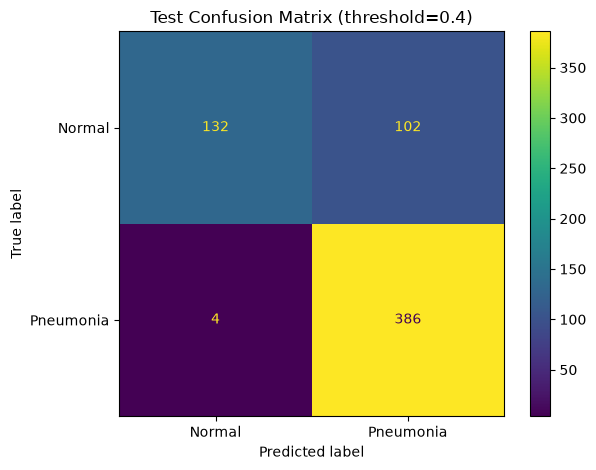

In [20]:

import time
import numpy as np
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Load the best checkpoint
checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=True
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Use the threshold selected on validation data
FINAL_THRESHOLD = 0.40

test_true = []
test_prob = []

start_time = time.perf_counter()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        logits = model(images)
        probabilities = torch.softmax(logits, dim=1)[:, 1]

        test_true.extend(labels.numpy())
        test_prob.extend(probabilities.cpu().numpy())

elapsed = time.perf_counter() - start_time

test_true = np.asarray(test_true)
test_prob = np.asarray(test_prob)
test_pred = (test_prob >= FINAL_THRESHOLD).astype(int)

# Confusion matrix: rows = actual, columns = predicted
tn, fp, fn, tp = confusion_matrix(
    test_true, test_pred, labels=[0, 1]
).ravel()

specificity = tn / (tn + fp) if (tn + fp) else 0.0
sensitivity = recall_score(
    test_true, test_pred, zero_division=0
)

print("FINAL TEST-SET RESULTS")
print("=" * 45)
print("Checkpoint epoch:", checkpoint["epoch"])
print("Classification threshold:", FINAL_THRESHOLD)
print(f"Accuracy:             {accuracy_score(test_true, test_pred):.4f}")
print(f"Precision:            {precision_score(test_true, test_pred, zero_division=0):.4f}")
print(f"Sensitivity / Recall: {sensitivity:.4f}")
print(f"Specificity:          {specificity:.4f}")
print(f"F1-score:             {f1_score(test_true, test_pred, zero_division=0):.4f}")
print(f"ROC-AUC:              {roc_auc_score(test_true, test_prob):.4f}")
print(f"Average Precision:    {average_precision_score(test_true, test_prob):.4f}")
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(f"Evaluation time:      {elapsed:.3f} seconds")
print(f"Time per image:       {elapsed / len(test_true) * 1000:.3f} ms")

print("\nClassification report:")
print(classification_report(
    test_true,
    test_pred,
    labels=[0, 1],
    target_names=["Normal", "Pneumonia"],
    digits=4,
    zero_division=0
))

# Plot the confusion matrix
cm = confusion_matrix(test_true, test_pred, labels=[0, 1])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Pneumonia"]
)
display.plot(values_format="d")
plt.title(f"Test Confusion Matrix (threshold={FINAL_THRESHOLD})")
plt.tight_layout()
plt.show()


In [21]:

from pathlib import Path
from PIL import Image

# Save one image from the official test dataset
output_path = Path.cwd() / "pneumonia_test_sample.png"

# The test dataset contains images and labels
sample_index = 0
sample_image = test_dataset.imgs[sample_index]
sample_label = int(test_dataset.labels[sample_index].reshape(-1)[0])

Image.fromarray(sample_image).convert("L").save(output_path)

print("Image saved to:", output_path.resolve())
print("Actual class:", "Pneumonia" if sample_label == 1 else "Normal")


Image saved to: C:\Users\dhwan\OneDrive\Desktop\5_ISC_PROJECT\medsecure-ai\ml\notebooks\pneumonia_test_sample.png
Actual class: Pneumonia
